Circular task analysis

In [26]:
# imports (this is all you need for this assignment - please, do not import anything else)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle , Circle
import os
# very useful for plots that yo can zoom in-out
%matplotlib inline
# if the present working directory is the directory of this file, change the path to the project root
if os.getcwd().endswith("notebooks"):
    os.chdir("..")

In [27]:
data_file = "data/data.csv"
marker_file = "data/marker.csv"

with open(data_file) as f:
    first_line = f.readline().strip()
header = {}
for item in first_line.split(";"):
    name, value = item.split(" ", 1)
    header[name] = value
print(f"Header line information in '{data_file}':")
for name, value in header.items():
    print(f"  {name}: {value}")

cx, cy = float(header["centerX"]), float(header["centerY"])
Rt = float(header["taskRadius"])
tol = float(header["taskTolerance"])
W, H = float(header["screenWidth"]), float(header["screenHeight"])

with open(marker_file) as f:
    lines = f.read().splitlines()
markers = []
for line in lines[3:]:
    parts = line.split(",", 2)
    if len(parts) == 3 and parts[1].strip().isdigit():
        markers.append((int(parts[1]), parts[2]))
print(f"\nMarkers in '{marker_file}':")
for ts, text in markers:
    print(f"{ts}: {text}")

Header line information in 'data/data.csv':
  software: mouseReMoCo
  version: 1.3.0
  isWithLSL: false
  screenWidth: 1350
  screenHeight: 689
  centerX: 675
  centerY: 344
  autoStart: 3600
  cycleMaxNumber: 6
  cycleDuration: 20
  borderColor: java.awt.Color[r=255,g=255,b=255]
  textColor: java.awt.Color[r=255,g=255,b=255]
  backgroundColor: java.awt.Color[r=0,g=0,b=0]
  cursorColorRecord: java.awt.Color[r=255,g=0,b=0]
  cursorColorWait: java.awt.Color[r=255,g=255,b=0]
  task: circular
  cornerX: 411
  cornerY: 80
  externalRadius: 264
  internalRadius: 184
  borderRadius: 1
  cursorRadius: 16
  indexOfDifficulty: 29.878551407545476
  taskRadius: 223.5
  taskTolerance: 47

Markers in 'data/marker.csv':
1794401436012: KeyTyped=32 ASCI=  DoCycleChange
1794401436014: DoCycleChange:DoStartCycleTimedSequence
1794401436015: DoCycleChange:DoRecord RecordDone=0 PauseDone=0 ToDo=6
1794401456016: DoCycleChange:DoPause RecordDone=1 PauseDone=0 ToDo=6
1794401459237: KeyTyped=32 ASCI=  DoCycleCh

In [28]:
# data: timestamp (ms), mouseX, mouseY, mouseInTarget
d = np.loadtxt(data_file, delimiter=",", skiprows=4)
d = d[d[:, 0] > 0]
t0 = d[0, 0]                                   # time zero = first sample
ts = (d[:, 0] - t0) / 1000                     # time in seconds
x = d[:, 1] - cx                               # origin at the screen center
y = -(d[:, 2] - cy)                            # y axis pointing up
inside = d[:, 3]

# record start = DoRecord marker, record end = next DoPause marker
starts = [m[0] for m in markers if "DoRecord" in m[1]]
pauses = [m[0] for m in markers if "DoPause" in m[1]]
ends = pauses[:len(starts)]
ends += [int(d[-1, 0])] * (len(starts) - len(ends))

print("record times (seconds since the first sample):")
for s, e in zip(starts, ends):
    print(f"{(s - t0)/1000:7.3f} to {(e - t0)/1000:7.3f} ({(e - s)/1000:.3f} s)")

record times (seconds since the first sample):
 -1.048 to  18.953 (20.001 s)
 22.176 to  42.177 (20.001 s)
 43.881 to  63.882 (20.001 s)
 65.590 to  85.591 (20.001 s)
 88.080 to 108.081 (20.001 s)


In [29]:
records = []
for s, e in zip(starts, ends):
    m = (d[:, 0] >= s) & (d[:, 0] <= e)
    records.append(dict(t=ts[m], x=x[m], y=y[m], inside=inside[m]))

print("Number of records:", len(records))
for i, r in enumerate(records):
    dur = r["t"][-1] - r["t"][0]
    print(f"record {i}: {len(r['t'])} samples from {r['t'][0]:7.3f} to {r['t'][-1]:7.3f} s, ({dur:.3f}s, {(len(r['t'])-1)/dur:.3f} Hz)")

Number of records: 5
record 0: 527 samples from   0.000 to  18.945 s, (18.945s, 27.765 Hz)
record 1: 413 samples from  23.921 to  41.971 s, (18.050s, 22.825 Hz)
record 2: 357 samples from  45.757 to  62.470 s, (16.713s, 21.301 Hz)
record 3: 431 samples from  67.036 to  85.587 s, (18.551s, 23.179 Hz)
record 4: 441 samples from  89.407 to 107.821 s, (18.414s, 23.895 Hz)


Statistics table

In [30]:
def stats(r):
    # skip the approach phase: start at the first sample inside the target
    k = np.argmax(r["inside"] == 1)
    t, xx, yy, ins = r["t"][k:], r["x"][k:], r["y"][k:], r["inside"][k:]
    radius = np.hypot(xx, yy)
    angle = np.unwrap(np.arctan2(yy, xx))
    nLaps = (angle[-1] - angle[0]) / (2*np.pi)     
    Re = radius.mean()                             
    Te = 4.133 * radius.std()                     
    error = 100 * (1 - ins.mean())                 
    MT = (t[-1] - t[0]) / abs(nLaps)             
    IDe = 2*np.pi*Re / Te                         
    Be = Te / tol                                  
    IPe = IDe / MT                                  
    return [nLaps, Re, Te, error, MT, IDe, Be, IPe]

# theoretical error: normal distribution with Te = 4.133 sd -> tolerance = +-2.0665 sd
u = np.linspace(4.133/2, 10, 100000)
theory_error = 200 * np.sum(np.exp(-u**2/2) / np.sqrt(2*np.pi)) * (u[1] - u[0])

print("recomputed statistics for all records:")
print("   Var , nLaps ,      Re ,      Te ,   error ,  MT/lap , IDe/lap ,      Be ,     IPe ,")
print("  unit ,   lap ,   pixel ,   pixel ,       % ,   s/lap , bit/lap ,  double ,   bit/s ,")
print(f"Theory , {1:5.2f} , {Rt:7.2f} , {tol:7.2f} , {theory_error:7.2f} ,         ,         , {1:7.2f} ,         ,")
for i, r in enumerate(records):
    s = stats(r)
    print(f"Rec{i+1:03d} ," + " ,".join(f"{v:8.2f}" for v in s) + " ,")

recomputed statistics for all records:
   Var , nLaps ,      Re ,      Te ,   error ,  MT/lap , IDe/lap ,      Be ,     IPe ,
  unit ,   lap ,   pixel ,   pixel ,       % ,   s/lap , bit/lap ,  double ,   bit/s ,
Theory ,  1.00 ,  223.50 ,   47.00 ,    3.88 ,         ,         ,    1.00 ,         ,
Rec001 ,   -1.17 ,  220.52 ,   19.11 ,    0.00 ,   16.14 ,   72.51 ,    0.41 ,    4.49 ,
Rec002 ,   -1.08 ,  221.59 ,   17.95 ,    0.00 ,   16.69 ,   77.58 ,    0.38 ,    4.65 ,
Rec003 ,   -1.18 ,  223.17 ,   28.64 ,    0.00 ,   14.19 ,   48.97 ,    0.61 ,    3.45 ,
Rec004 ,   -1.24 ,  223.90 ,   26.54 ,    0.00 ,   14.98 ,   53.00 ,    0.56 ,    3.54 ,
Rec005 ,   -1.26 ,  223.12 ,   24.89 ,    0.00 ,   14.61 ,   56.32 ,    0.53 ,    3.85 ,


Raw plots

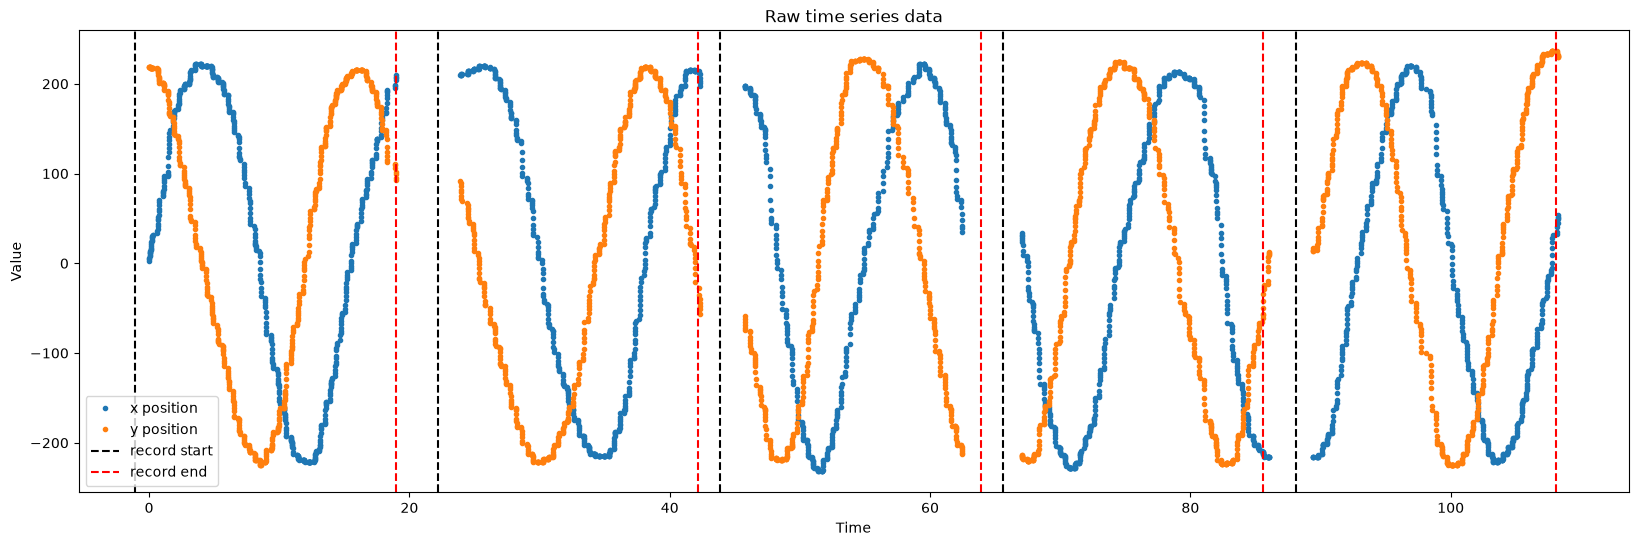

In [31]:
# raw time series
plt.figure(figsize=(20, 6))
plt.plot(ts, x, ".", label="x position")
plt.plot(ts, y, ".", label="y position")
for i, (s, e) in enumerate(zip(starts, ends)):
    plt.axvline((s - t0)/1000, color="k", ls="--", label="record start" if i == 0 else None)
    plt.axvline((e - t0)/1000, color="r", ls="--", label="record end" if i == 0 else None)
plt.title("Raw time series data")
plt.xlabel("Time"); plt.ylabel("Value")
plt.legend()
plt.show()

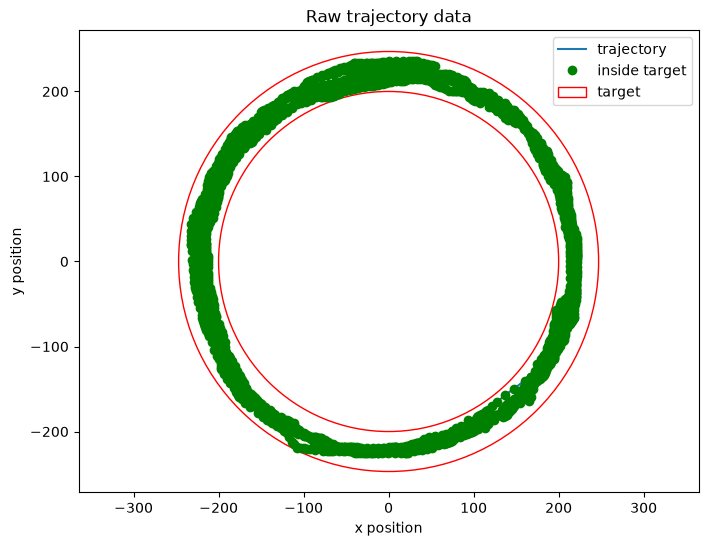

In [32]:
# raw trajectory (all records together) with the target ring
plt.figure(figsize=(8, 6))
ax = plt.gca()
for i, r in enumerate(records):
    plt.plot(r["x"], r["y"], "C0", label="trajectory" if i == 0 else None)
plt.plot(x[inside == 1], y[inside == 1], "go", label="inside target")
ax.add_patch(Circle((0, 0), Rt + tol/2, fill=False, ec="red", label="target"))
ax.add_patch(Circle((0, 0), Rt - tol/2, fill=False, ec="red"))
plt.title("Raw trajectory data")
plt.xlabel("x position"); plt.ylabel("y position")
plt.axis("equal")
plt.legend()
plt.show()

One figure per record (trajectory + time series)

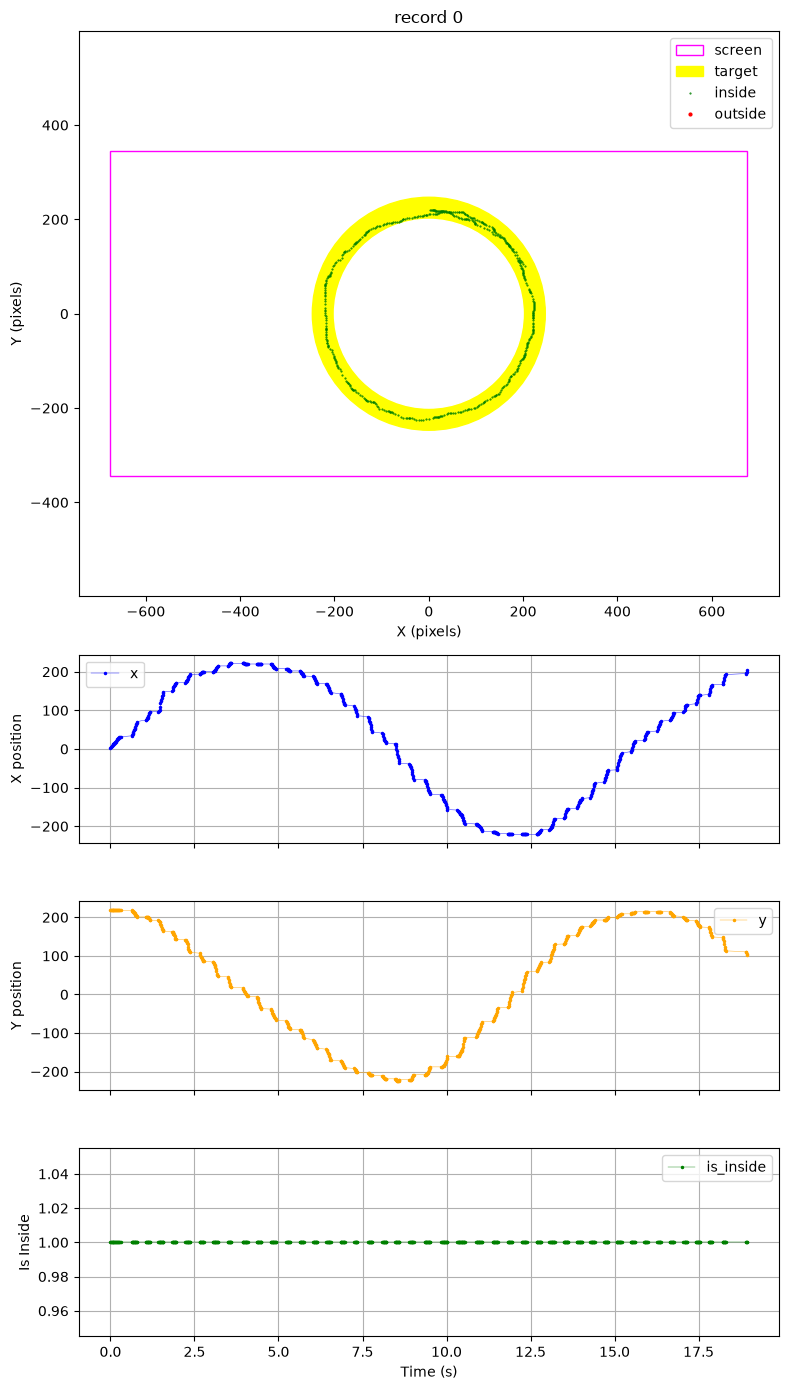

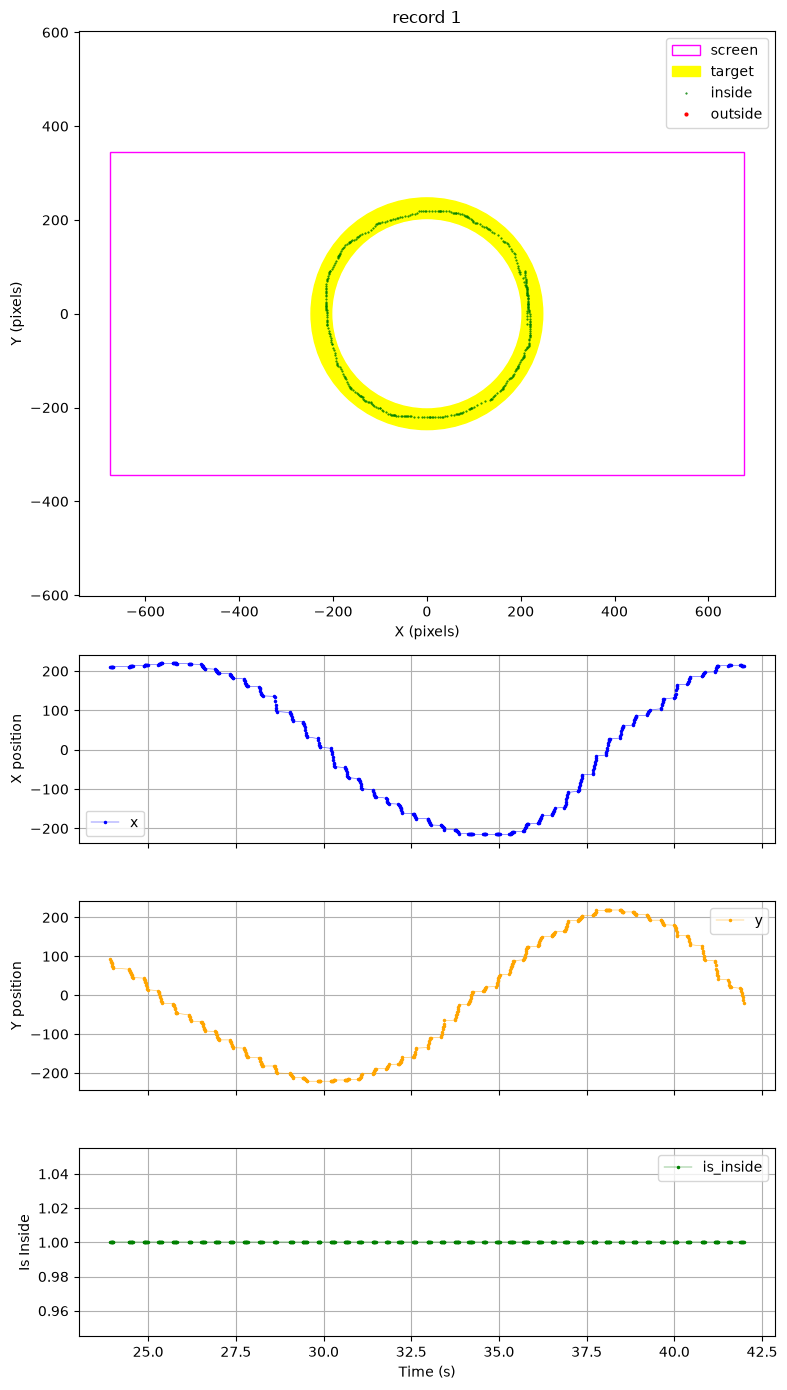

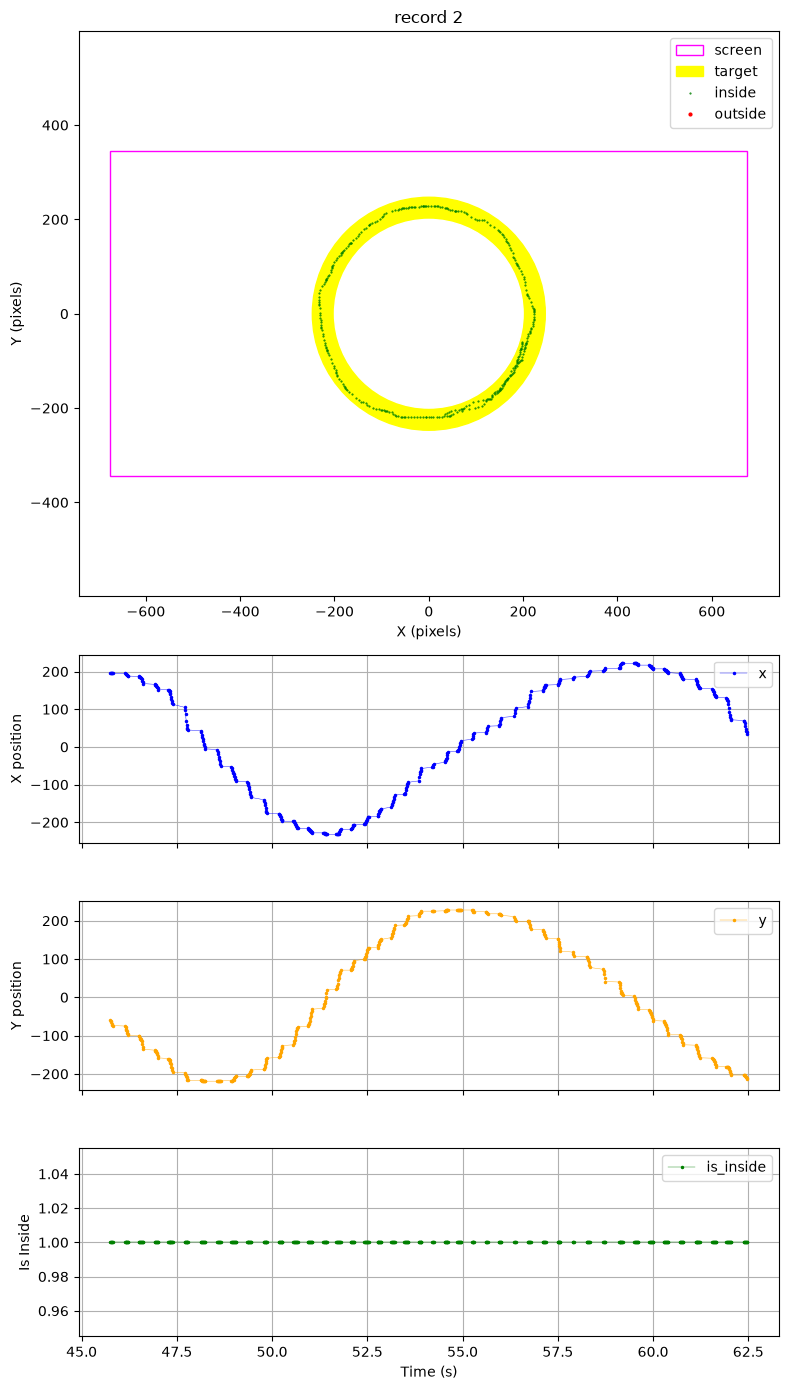

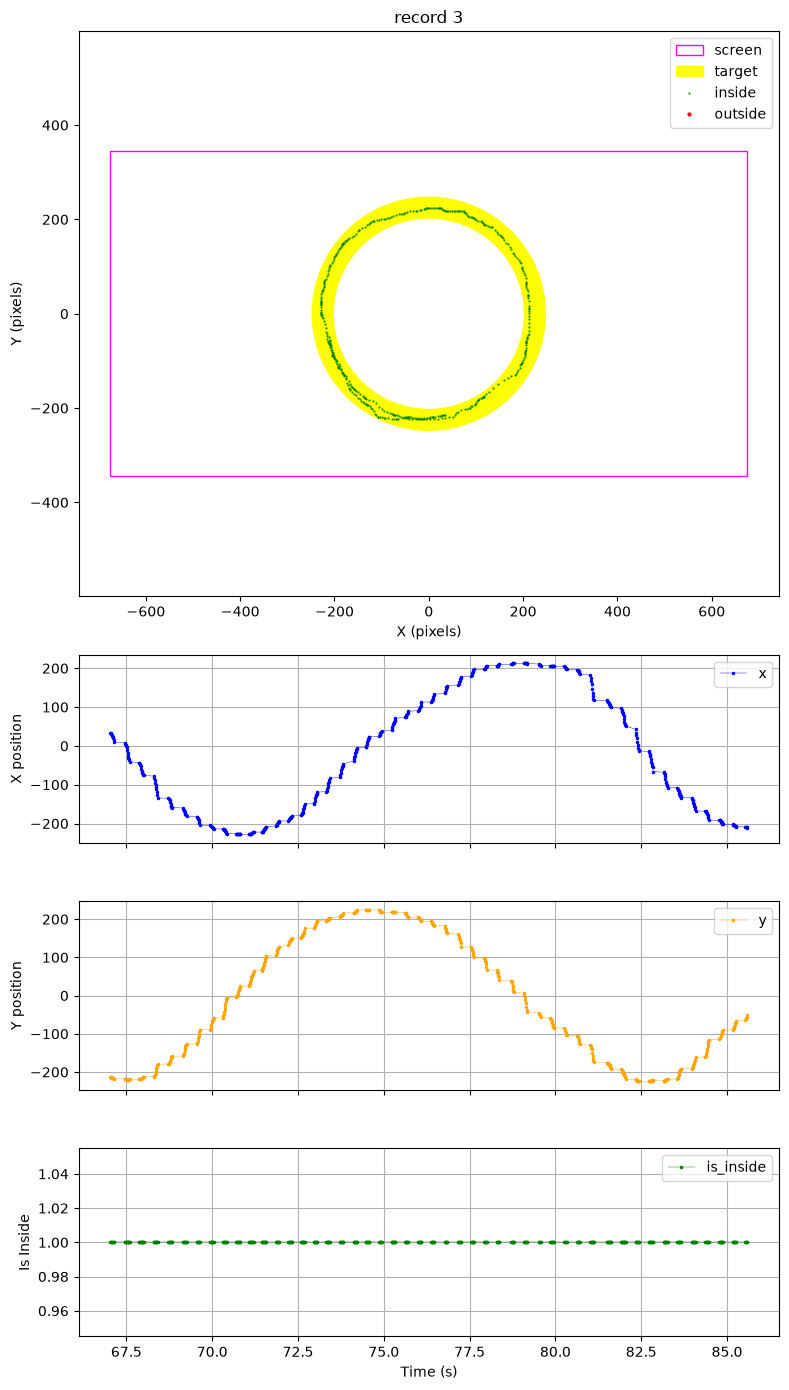

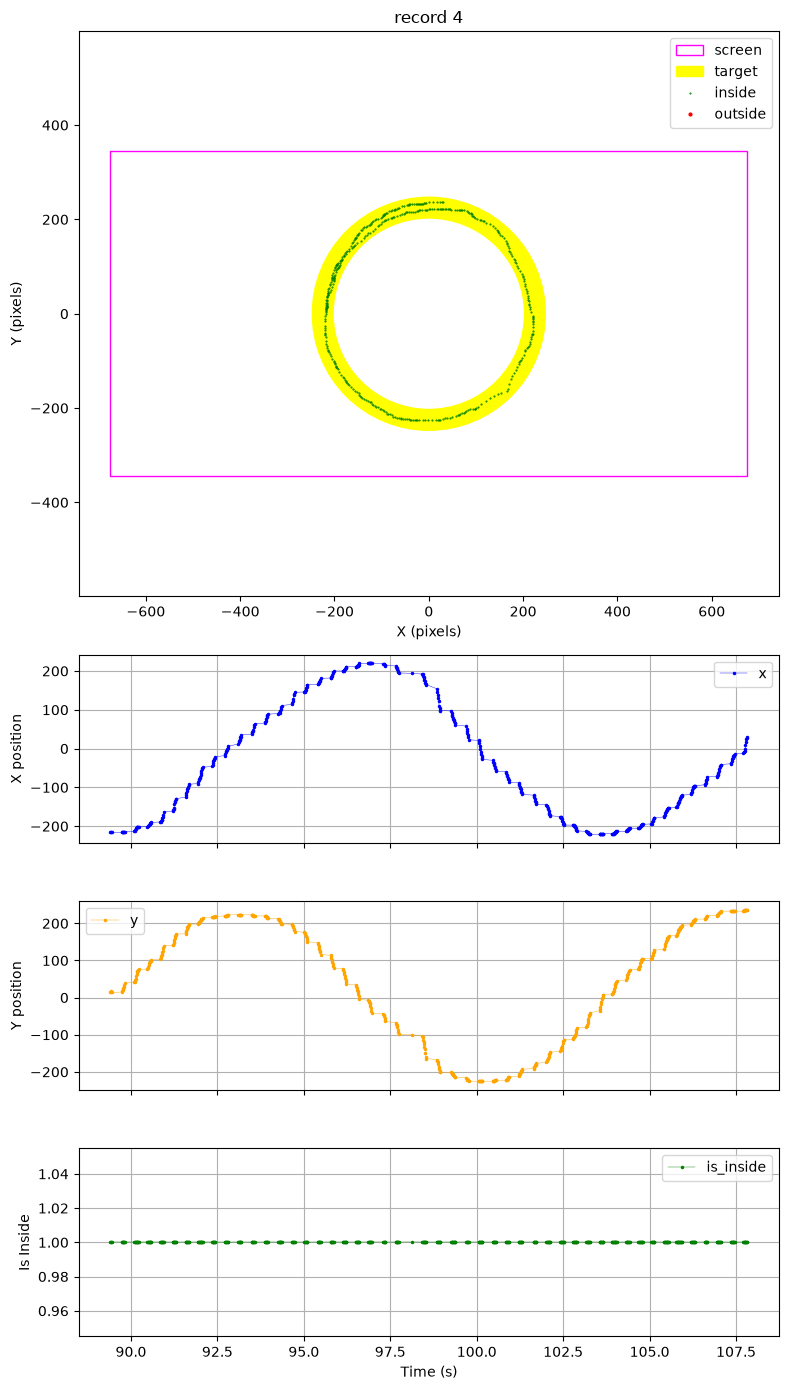

In [33]:
def plot_record(r, i):
    # ONE figure per record: trajectory on top, then x, y and is_inside over time
    fig, axs = plt.subplots(4, 1, figsize=(8, 14), gridspec_kw={"height_ratios": [3, 1, 1, 1]})
    ax = axs[0]
    ax.add_patch(Rectangle((-W/2, -H/2), W, H, fill=False, ec="magenta", label="screen"))
    ax.add_patch(Circle((0, 0), Rt + tol/2, color="yellow", label="target"))
    ax.add_patch(Circle((0, 0), Rt - tol/2, color="white"))
    ins = r["inside"] == 1
    ax.plot(r["x"][ins], r["y"][ins], "g.", ms=1, label="inside")
    ax.plot(r["x"][~ins], r["y"][~ins], "r.", ms=4, label="outside")
    ax.set_title(f"record {i}")
    ax.set_xlabel("X (pixels)"); ax.set_ylabel("Y (pixels)")
    ax.axis("equal")
    ax.legend(loc="upper right")

    axs[1].plot(r["t"], r["x"], "b.-", ms=3, lw=0.3, label="x"); axs[1].set_ylabel("X position")
    axs[2].plot(r["t"], r["y"], ".-", color="orange", ms=3, lw=0.3, label="y"); axs[2].set_ylabel("Y position")
    axs[3].plot(r["t"], r["inside"], "g.-", ms=3, lw=0.3, label="is_inside"); axs[3].set_ylabel("Is Inside")
    axs[3].set_xlabel("Time (s)")
    for a in axs[1:]:
        a.grid(True); a.legend()
        a.sharex(axs[1])
    for a in axs[1:3]:
        a.tick_params(labelbottom=False)
    plt.tight_layout()
    plt.show()

for i, r in enumerate(records):
    plot_record(r, i)